In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [71]:
cat119 = pd.read_csv('cat119_train.csv', encoding='cp949')
cat119 = cat119[['cat119_train.tm', 'cat119_train.call_count', 'cat119_train.address_city']]
cat119.columns = ['날짜', '신고건수', '시']

cat119['날짜'] = cat119['날짜'].astype(str).str.lstrip('0')
cat119['날짜'] = pd.to_datetime(cat119['날짜'], format='%Y%m%d')

cat119_daily = cat119.groupby(['날짜', '시'])['신고건수'].sum().reset_index()
print(cat119_daily.head())

          날짜      시  신고건수
0 2020-05-01  부산광역시    89
1 2020-05-02  부산광역시    81
2 2020-05-03  부산광역시    74
3 2020-05-04  부산광역시    97
4 2020-05-05  부산광역시    70


In [72]:
weather_files = ['wea_2020.csv', 'wea_2021.csv', 'wea_2022.csv', 'wea_2023.csv', 'wea_2024.csv']
weather_dfs = [pd.read_csv(f, encoding='cp949') for f in weather_files]

for df in weather_dfs:
    df.rename(columns={
        '일시': '날짜',
        '최고기온(°C)': '최고기온',
        '최저기온(°C)': '최저기온',
        '일강수량(mm)': '일강수량',
        '최대 순간 풍속(m/s)': '최대순간풍속',
        '최대 풍속(m/s)': '최대풍속',
        '최소 상대습도(%)': '습도'
    }, inplace=True)

weather_all = pd.concat(weather_dfs, ignore_index=True)
weather_all['날짜'] = pd.to_datetime(weather_all['날짜'])

# 결측치 처리 (이동평균)
for col in ['최고기온', '최저기온', '일강수량', '최대순간풍속', '최대풍속', '습도']:
    weather_all[col] = weather_all[col].fillna(weather_all[col].rolling(3, min_periods=1).mean())

weather_selected = weather_all[['날짜', '최고기온', '최저기온', '일강수량', '최대순간풍속', '최대풍속', '습도']]
print(weather_selected.head())

          날짜  최고기온  최저기온  일강수량  최대순간풍속  최대풍속    습도
0 2020-05-01  22.7  16.7   NaN    14.4   9.4  64.0
1 2020-05-02  21.8  17.0   1.1    10.0   6.5  69.0
2 2020-05-03  17.9  16.2  21.3     9.3   5.0  89.0
3 2020-05-04  25.0  15.8  11.2     9.1   6.8  63.0
4 2020-05-05  18.5  14.2  21.3     8.3   4.2  68.0


In [73]:
merged = pd.merge(cat119_daily, weather_selected, on='날짜', how='left')
cols_to_keep = ['날짜', '시', '신고건수', '최고기온', '최저기온', '일강수량', '최대순간풍속', '최대풍속', '습도']
merged = merged[cols_to_keep]
print(merged.head())

          날짜      시  신고건수  최고기온  최저기온  일강수량  최대순간풍속  최대풍속    습도
0 2020-05-01  부산광역시    89  22.7  16.7   NaN    14.4   9.4  64.0
1 2020-05-02  부산광역시    81  21.8  17.0   1.1    10.0   6.5  69.0
2 2020-05-03  부산광역시    74  17.9  16.2  21.3     9.3   5.0  89.0
3 2020-05-04  부산광역시    97  25.0  15.8  11.2     9.1   6.8  63.0
4 2020-05-05  부산광역시    70  18.5  14.2  21.3     8.3   4.2  68.0


In [74]:
train_data = merged[(merged['날짜'] >= '2020-05-01') & (merged['날짜'] <= '2023-10-31')].copy()

weather_2024 = weather_selected[(weather_selected['날짜'] >= '2024-05-01') & (weather_selected['날짜'] <= '2024-10-31')].copy()

print('train_data shape:', train_data.shape)
print('weather_2024 shape:', weather_2024.shape)

train_data shape: (920, 9)
weather_2024 shape: (368, 7)


In [75]:
train_data['일강수량'] = train_data['일강수량'].fillna(0)
for col in ['최고기온', '최저기온', '최대순간풍속', '최대풍속', '습도']:
    train_data[col] = train_data[col].fillna(train_data[col].mean())

for col in ['최고기온', '최저기온', '일강수량', '최대순간풍속', '최대풍속', '습도']:
    if col == '일강수량':
        weather_2024[col] = weather_2024[col].fillna(0)
    else:
        weather_2024[col] = weather_2024[col].fillna(weather_2024[col].mean())

print("train_data 결측치:\n", train_data.isnull().sum())
print("weather_2024 결측치:\n", weather_2024.isnull().sum())

train_data 결측치:
 날짜        0
시         0
신고건수      0
최고기온      0
최저기온      0
일강수량      0
최대순간풍속    0
최대풍속      0
습도        0
dtype: int64
weather_2024 결측치:
 날짜        0
최고기온      0
최저기온      0
일강수량      0
최대순간풍속    0
최대풍속      0
습도        0
dtype: int64


In [76]:
from sklearn.preprocessing import MinMaxScaler

X_train = train_data[['최고기온', '최저기온', '일강수량', '최대순간풍속', '최대풍속', '습도']].values
y_train = train_data['신고건수'].values
X_pred = weather_2024[['최고기온', '최저기온', '일강수량', '최대순간풍속', '최대풍속', '습도']].values

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))
X_pred_scaled = scaler_X.transform(X_pred)

In [77]:
def create_sequences(X, y=None, look_back=7, pred_mode=False):
    Xs, ys = [], []
    for i in range(len(X) - look_back):
        Xs.append(X[i:i+look_back])
        if not pred_mode and y is not None:
            ys.append(y[i+look_back])
    if pred_mode:
        return np.array(Xs)
    else:
        return np.array(Xs), np.array(ys)

look_back = 7
X_train_seq, y_train_seq = create_sequences(X_train_scaled, y_train_scaled, look_back)
X_pred_seq = create_sequences(X_pred_scaled, look_back=look_back, pred_mode=True)
print("X_pred_seq NaN 개수:", np.isnan(X_pred_seq).sum())

X_pred_seq NaN 개수: 0


In [78]:
lstm_model = Sequential([
    LSTM(128, activation='relu', return_sequences=True, input_shape=(look_back, X_train_seq.shape[2])),
    Dropout(0.3),
    LSTM(64, activation='relu'),
    Dropout(0.3),
    Dense(1)
])
es = EarlyStopping(monitor='val_loss', patience=10, verbose=1, restore_best_weights=True)
lstm_model.compile(optimizer=Adam(0.001), loss='mse')
lstm_history = lstm_model.fit(
    X_train_seq, y_train_seq,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    callbacks=[es],
    verbose=1
)

C:\Users\homie\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 9s 75ms/step - loss: 0.0019 - val_loss: 4.0123e-04
Epoch 2/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0017 - val_loss: 3.8890e-04
Epoch 3/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.0010 - val_loss: 3.9171e-04
Epoch 4/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 5.0777e-04 - val_loss: 3.7905e-04
Epoch 5/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0028 - val_loss: 3.8816e-04
Epoch 6/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0010 - val_loss: 4.1201e-04
Epoch 7/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0031 - val_loss: 3.8373e-04
Epoch 8/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0014 - val_loss: 3.9555e-04
Epoch 9/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 3.1400e-04 - val_loss: 4.0542e-04
Epoch 10/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 9.6624e-04 - val_loss: 4.0725e-04
Epoch 11/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0030 - val_loss: 3.7242e

In [79]:
X_train_flat = X_train_seq.reshape(X_train_seq.shape[0], -1)
X_pred_flat = X_pred_seq.reshape(X_pred_seq.shape[0], -1)
mlp_model = Sequential([
    Dense(256, activation='relu', input_shape=(X_train_flat.shape[1],)),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1)
])
mlp_model.compile(optimizer=Adam(0.001), loss='mse')
mlp_history = mlp_model.fit(
    X_train_flat, y_train_seq,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    callbacks=[es],
    verbose=1
)

Epoch 1/200


C:\Users\homie\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0292 - val_loss: 5.8004e-04
Epoch 2/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0039 - val_loss: 4.7792e-04
Epoch 3/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0031 - val_loss: 5.5466e-04
Epoch 4/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0033 - val_loss: 4.0139e-04
Epoch 5/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0022 - val_loss: 4.3815e-04
Epoch 6/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0025 - val_loss: 3.7313e-04
Epoch 7/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0020 - val_loss: 3.7369e-04
Epoch 8/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0036 - val_loss: 4.0888e-04
Epoch 9/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0025 - val_loss: 4.0935e-04
Epoch 10/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0015 - val_loss: 4.0014e-04
Epoch 11/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0023 - val_loss: 3.9317e-04
Epoch 12/200
23/23 ━

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


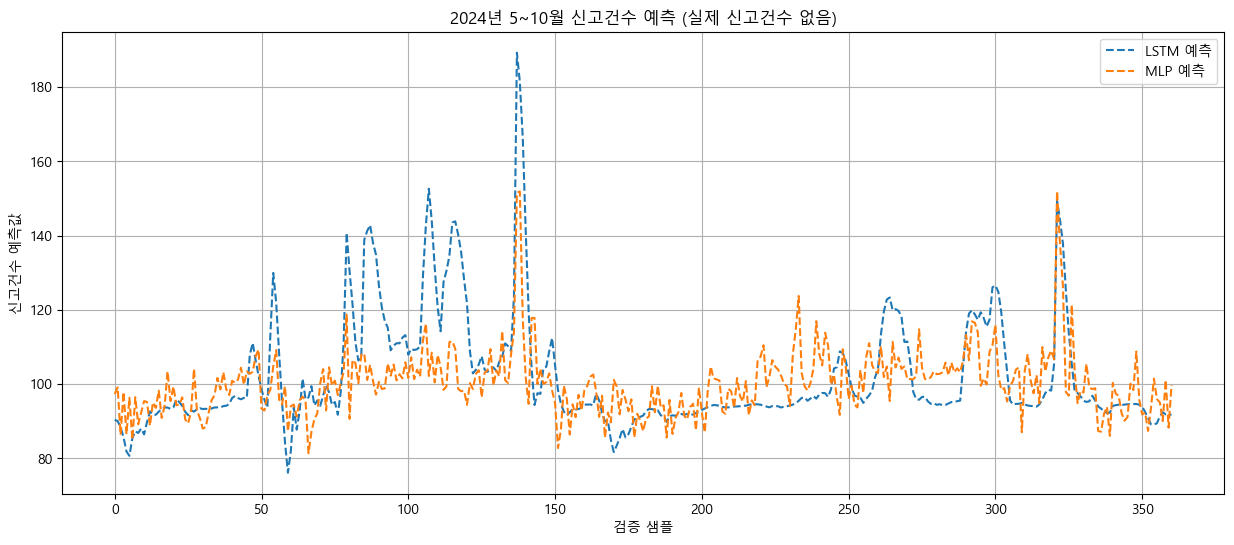

In [80]:
lstm_pred = lstm_model.predict(X_pred_seq)
mlp_pred = mlp_model.predict(X_pred_flat)
lstm_pred_inv = scaler_y.inverse_transform(lstm_pred)
mlp_pred_inv = scaler_y.inverse_transform(mlp_pred)

import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(15,6))
plt.plot(lstm_pred_inv, label='LSTM 예측', linestyle='--')
plt.plot(mlp_pred_inv, label='MLP 예측', linestyle='--')
plt.title('2024년 5~10월 신고건수 예측 (실제 신고건수 없음)')
plt.xlabel('검증 샘플')
plt.ylabel('신고건수 예측값')
plt.legend()
plt.grid(True)
plt.show()

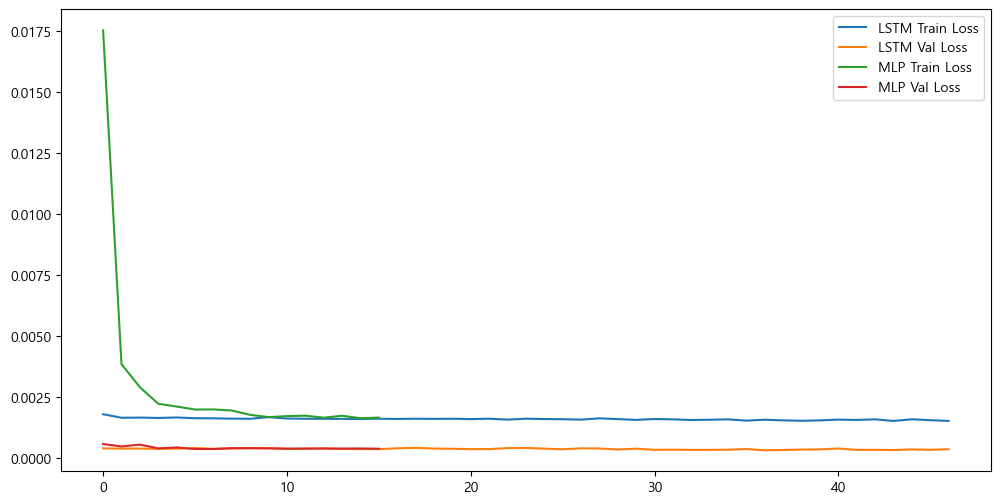

In [81]:
plt.figure(figsize=(12,6))
plt.plot(lstm_history.history['loss'], label='LSTM Train Loss')
plt.plot(lstm_history.history['val_loss'], label='LSTM Val Loss')
plt.plot(mlp_history.history['loss'], label='MLP Train Loss') 
plt.plot(mlp_history.history['val_loss'], label='MLP Val Loss')
plt.legend()
plt.show()

In [87]:
print(f"LSTM 예측 범위: {lstm_pred_inv.min():.1f} ~ {lstm_pred_inv.max():.1f}")
print(f"MLP 예측 범위: {mlp_pred_inv.min():.1f} ~ {mlp_pred_inv.max():.1f}")
print(f"LSTM 예측 평균: {lstm_pred_inv.mean():.1f}")
print(f"MLP 예측 평균: {mlp_pred_inv.mean():.1f}")

LSTM 예측 범위: 76.1 ~ 189.2
MLP 예측 범위: 81.4 ~ 152.0
LSTM 예측 평균: 102.0
MLP 예측 평균: 100.2
